# 02 — Terrain dan evaluasinya

Padanan evaluasi DEM vs grid levelling di paper (Fig. 4, 14, 15):

1. DEMNAS → clip AOI + 3 km, reproject + resample ke grid 8 m UTM 48S.
2. Copernicus GLO-30 → grid yang sama.
3. ICESat-2 ATL08 (`terrain/h_te_best_fit`, segmen 100 m) sebagai referensi; buang fill dan uncertainty tinggi.
   Data diambil lewat SlideRule (`raw/icesat2_atl08_ui.gpkg`), bukan `earthaccess`, agar tanpa akun Earthdata.
4. Konversi tinggi ICESat-2 ellipsoid WGS84 → EGM2008.
5. `ΔZ = Z_DEM − Z_ICESat2`, statistik setara paper, histogram kelas 0,2 m, scatter, permukaan 3D.

**Output**: `output/dem_ui_8m.tif`, `interim/copdem_ui_8m.tif`, `interim/terrain_points.gpkg`,
`output/terrain_eval.csv`, 3 figure.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import pyproj
import rasterio
from pyproj import Transformer
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject

from ui3d_common import CFG, CRS, aoi, fig_path, interim, out, raw, savefig

T = CFG["terrain"]
RES = T["grid_m"]
aoi_t = aoi("aoi_terrain")

## 1–2. DEMNAS dan Copernicus ke grid 8 m yang sama

In [2]:
x0, y0, x1, y1 = aoi_t.total_bounds
x0, y0 = np.floor(x0 / RES) * RES, np.floor(y0 / RES) * RES
W, H = int(np.ceil((x1 - x0) / RES)), int(np.ceil((y1 - y0) / RES))
GRID_TR = from_origin(x0, y0 + H * RES, RES, RES)


def to_grid(src_path, dst_path):
    with rasterio.open(src_path) as s:
        dst = np.full((H, W), np.nan, "float32")
        reproject(rasterio.band(s, 1), dst, src_crs=s.crs or "EPSG:4326", src_nodata=s.nodata,
                  dst_transform=GRID_TR, dst_crs=CRS, dst_nodata=np.nan, resampling=Resampling.bilinear)
    prof = dict(driver="GTiff", height=H, width=W, count=1, dtype="float32", crs=CRS, transform=GRID_TR,
                nodata=np.nan, compress="deflate")
    with rasterio.open(dst_path, "w", **prof) as d:
        d.write(dst, 1)
    return dst


dems = {"DEMNAS": to_grid(raw("demnas"), out("dem_ui_8m.tif")),
        "Copernicus GLO-30": to_grid(raw("copdem"), interim("copdem_ui_8m.tif"))}
for k, v in dems.items():
    print(f"{k}: {v.shape}, {np.nanmin(v):.1f}–{np.nanmax(v):.1f} m, NaN {np.isnan(v).mean():.1%}")

DEMNAS: (1150, 938), 27.3–100.0 m, NaN 0.0%
Copernicus GLO-30: (1150, 938), 29.8–108.8 m, NaN 0.0%


## 3. ICESat-2 ATL08: filter fill dan uncertainty

In [3]:
pts = gpd.read_file(raw("icesat2"), layer="atl08_100m")
print("CRS file:", pts.crs, "| segmen:", len(pts))
FILL = 1e30
h = pts["terrain/h_te_best_fit"].astype(float)
u = pts["terrain/h_te_uncertainty"].astype(float)
ok = np.isfinite(h) & (h < FILL) & np.isfinite(u) & (u < FILL) & (u <= T["max_uncertainty_m"])
pts = pts[ok].copy()
print(f"Lolos filter: {len(pts)} segmen (uncertainty <= {T['max_uncertainty_m']} m)")

CRS file: EPSG:7912 | segmen: 2254
Lolos filter: 1465 segmen (uncertainty <= 5.0 m)


## 4. Ellipsoid WGS84 → EGM2008

Butuh grid geoid PROJ (lihat `00_setup`). Bila grid tidak tersedia, PROJ diam-diam tidak mengubah tinggi,
jadi hasilnya dicek: selisih ellipsoid–geoid di Depok harus belasan meter, bukan 0.

In [4]:
pyproj.network.set_network_enabled(True)
t = Transformer.from_crs(CFG["crs"]["icesat2_src"], CFG["crs"]["vertical"], always_xy=True)
lon, lat = pts.geometry.x.values, pts.geometry.y.values
h_ell = pts["terrain/h_te_best_fit"].astype(float).values
_, _, h_egm = t.transform(lon, lat, h_ell)
N_geoid = h_ell - h_egm
assert np.abs(N_geoid).min() > 1, "Grid geoid EGM2008 tidak terpakai; jalankan sel geoid di 00_setup"
print(f"Undulasi geoid: {N_geoid.mean():.2f} ± {N_geoid.std():.2f} m")
pts["h_ellps"], pts["h_egm08"] = h_ell, h_egm
pts = pts.to_crs(CRS)

Undulasi geoid: 17.97 ± 0.07 m


## 5. Sampling DEM di titik ICESat-2 dan ΔZ

In [5]:
rows, cols = rasterio.transform.rowcol(GRID_TR, pts.geometry.x.values, pts.geometry.y.values)
rows, cols = np.asarray(rows), np.asarray(cols)
inside = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
pts = pts[inside].copy()
rows, cols = rows[inside], cols[inside]
for k, v in dems.items():
    pts[f"z_{k}"] = v[rows, cols]
    pts[f"dz_{k}"] = pts[f"z_{k}"] - pts["h_egm08"]
pts = pts.dropna(subset=[f"dz_{k}" for k in dems])

# Subset "tanah terbuka": jauh dari gedung OSM dan kanopi rendah (DEM radar = DSM).
# Catatan: footprint OSM di raw/ hanya mencakup AOI kampus, jadi di luar AOI filter ini hanya memakai kanopi.
bld = gpd.read_file(raw("osm"), layer="buildings").to_crs(CRS)
bld = bld[bld.geom_type.isin(["Polygon", "MultiPolygon"])]
dist = pts.geometry.apply(lambda p: bld.distance(p).min()) if len(bld) else np.inf
canopy = pd.to_numeric(pts.get("h_canopy"), errors="coerce")
canopy = canopy.where(canopy < FILL)  # index sama dengan pts
pts["open_ground"] = (dist > T["open_ground_dist_m"]) & (canopy.isna() | (canopy < T["open_ground_max_canopy_m"]))
print(f"Titik dipakai: {len(pts)}; tanah terbuka: {pts.open_ground.sum()}")
pts.drop(columns=[c for c in pts.columns if pts[c].dtype == object and c != "geometry"]).to_file(
    interim("terrain_points.gpkg"), layer="terrain_points")

Titik dipakai: 1249; tanah terbuka: 15


## 6. Statistik setara paper

In [6]:
def stats(dz):
    a = np.abs(dz)
    med = np.median(dz)
    s = dict(n=len(dz), min=dz.min(), max=dz.max(), mean=dz.mean(), median=med, std=dz.std(), max_abs=a.max(),
             rmse=np.sqrt(np.mean(dz ** 2)), nmad=1.4826 * np.median(np.abs(dz - med)), le90=np.percentile(a, 90))
    s.update({f"pct_abs_lt_{t}m": (a < t).mean() * 100 for t in T["thresholds_m"]})
    return s


rows_ = []
for k in dems:
    subsets = (("semua", np.ones(len(pts), bool)),
               (f"kanopi_lt_{T['low_canopy_m']:g}m", (canopy.isna() | (canopy < T["low_canopy_m"])).values),
               ("tanah_terbuka", pts.open_ground.values))
    for subset, m in subsets:
        if m.sum():
            rows_.append(dict(dem=k, subset=subset, **stats(pts.loc[m, f"dz_{k}"].values)))
ev = pd.DataFrame(rows_).round(3)
ev.to_csv(out("terrain_eval.csv"), index=False)
# NMAD = 1,4826 × median|ΔZ − median|: sebaran galat yang tahan pencilan (kanopi, atap, awan).
print(f"Titik dengan kanopi ICESat-2 < {T['low_canopy_m']:g} m: {int((canopy < T['low_canopy_m']).sum())}")
print("Paper (Mansoura): selisih maks. 0,85 m; 90% sel < 0,85 m")
ev

Titik dengan kanopi ICESat-2 < 5 m: 57
Paper (Mansoura): selisih maks. 0,85 m; 90% sel < 0,85 m


,dem,subset,n,min,max,mean,median,std,max_abs,rmse,nmad,le90,pct_abs_lt_0.2m,pct_abs_lt_0.4m,pct_abs_lt_0.65m,pct_abs_lt_0.85m
0,DEMNAS,semua,1249,-30.321,68.392,-0.611,-0.897,7.612,68.392,7.637,3.109,8.992,4.564,8.647,14.091,20.496
1,DEMNAS,kanopi_lt_5m,57,-16.827,68.054,-2.433,-5.572,17.723,68.054,17.889,5.485,16.716,0.000,0.000,0.000,3.509
2,DEMNAS,tanah_terbuka,15,-16.827,49.312,-6.806,-11.485,16.437,49.312,17.791,7.355,16.805,0.000,0.000,0.000,0.000
3,Copernicus GLO-30,semua,1249,-26.130,72.155,2.452,2.110,7.342,72.155,7.741,2.379,8.104,2.722,5.925,9.528,13.211
4,Copernicus GLO-30,kanopi_lt_5m,57,-10.582,72.022,2.631,-0.639,16.690,72.022,16.896,3.170,10.386,7.018,10.526,22.807,28.070
5,Copernicus GLO-30,tanah_terbuka,15,-2.778,50.725,3.971,-0.626,12.790,50.725,13.393,0.306,7.243,0.000,0.000,40.000,53.333


## Histogram |ΔZ| kelas 0,2 m (setara Fig. 15) dan scatter ΔZ (setara Fig. 14)

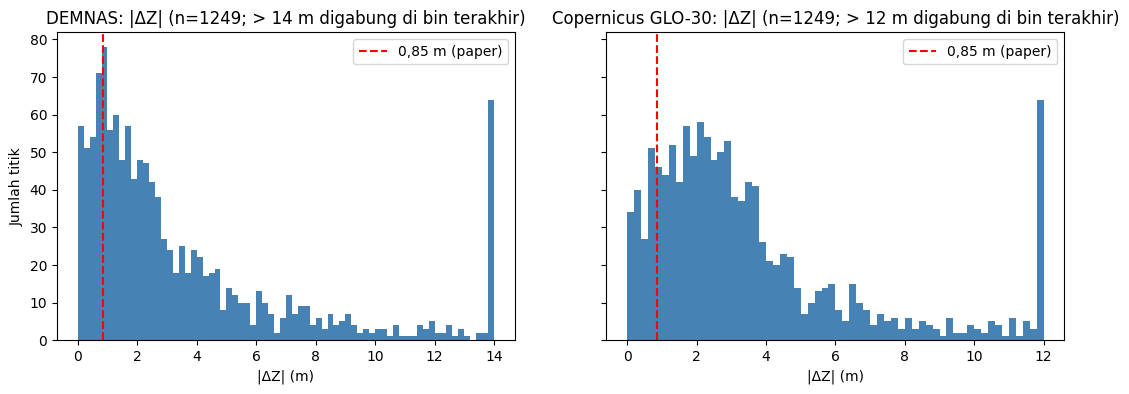

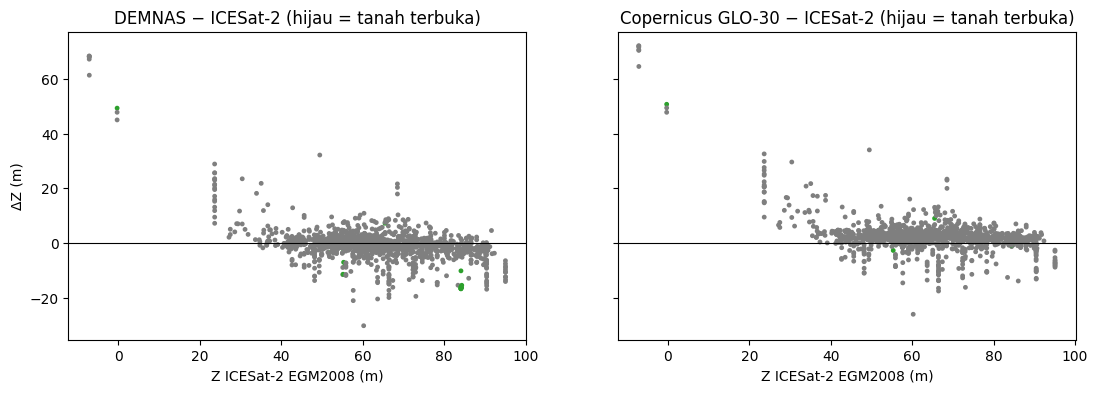

In [7]:
fig, ax = plt.subplots(1, len(dems), figsize=(13, 4), sharey=True)
for a, k in zip(ax, dems):
    v = np.abs(pts[f"dz_{k}"])
    top = max(1.0, np.ceil(np.percentile(v, 95)))
    a.hist(np.clip(v, 0, top), bins=np.arange(0, top + 0.2, 0.2), color="steelblue")
    a.axvline(0.85, color="r", ls="--", label="0,85 m (paper)")
    a.set(title=f"{k}: |ΔZ| (n={len(v)}; > {top:.0f} m digabung di bin terakhir)", xlabel="|ΔZ| (m)")
    a.legend()
ax[0].set_ylabel("Jumlah titik")
savefig(fig, "fig15_hist_dz.png")
plt.show()

fig, ax = plt.subplots(1, len(dems), figsize=(13, 4), sharey=True)
for a, k in zip(ax, dems):
    c = np.where(pts.open_ground, "tab:green", "tab:gray")
    a.scatter(pts["h_egm08"], pts[f"dz_{k}"], s=6, c=c)
    a.axhline(0, color="k", lw=0.8)
    a.set(title=f"{k} − ICESat-2 (hijau = tanah terbuka)", xlabel="Z ICESat-2 EGM2008 (m)")
ax[0].set_ylabel("ΔZ (m)")
savefig(fig, "fig14_scatter_dz.png")
plt.show()

## 7. Permukaan 3D terrain AOI (setara Fig. 4)

In [8]:
b = aoi().total_bounds
r0, c0 = rasterio.transform.rowcol(GRID_TR, b[0], b[3])
r1, c1 = rasterio.transform.rowcol(GRID_TR, b[2], b[1])
z = dems["DEMNAS"][r0:r1 + 1, c0:c1 + 1]
xs = GRID_TR.c + (np.arange(c0, c1 + 1) + 0.5) * RES
ys = GRID_TR.f - (np.arange(r0, r1 + 1) + 0.5) * RES
f3 = go.Figure(go.Surface(x=xs, y=ys, z=z, colorscale="Earth"))
f3.update_layout(title="Terrain DEMNAS 8 m — kampus UI", scene=dict(aspectmode="manual", aspectratio=dict(x=1, y=2, z=0.3)))
f3.write_html(fig_path("fig04_terrain_surface.html"))
f3.show()